# Performance Improvement Program: Case Study
**Part 1:** Partner benefit (points) program, budget under CPT < Rs 0.9  
**Part 2:** Partner Quality model, retraining threshold and escalation plan

*Run top to bottom. Shared logic lives in `core.py`; the Streamlit app (`app.py`) uses the same functions.*

## 0. Setup

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from core import *
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (8, 3.5)

# PART 1: Benefit Program Design

## 1.1 Load & validate data

In [3]:
d = load_supply()
print(d.shape, '| partners:', d.pid.nunique(), '| dates:', d.date.min().date(), 'to', d.date.max().date())
print('nulls:', d.isna().sum().sum(), '| duplicate partner-days:', d.duplicated(['pid','date']).sum())
print('days with hours > 16:', (d.hours > 16).sum(), '| max hours:', round(d.hours.max(), 1), '(impossible >24h -> cap needed)')
d.describe().T

(36313, 7) | partners: 1524 | dates: 2019-01-01 to 2019-04-30
nulls: 0 | duplicate partner-days: 0
days with hours > 16: 64 | max hours: 46.1 (impossible >24h -> cap needed)


,count,mean,min,25%,50%,75%,max,std
pid,36313.0,1324440.644012,233711.0,801579.0,1215321.0,1923101.0,2771806.0,683769.545169
date,36313,2019-03-02 11:43:38.533307648,2019-01-01 00:00:00,2019-01-31 00:00:00,2019-03-03 00:00:00,2019-04-02 00:00:00,2019-04-30 00:00:00,NaN
hours,36313.0,7.793744,0.000278,5.320278,8.168889,10.564722,46.06,3.640679
tasks,36313.0,11.636191,1.0,6.0,13.0,16.0,45.0,6.281271
dow,36313.0,2.946796,0.0,1.0,3.0,5.0,6.0,1.954125


**Finding:** clean data (no nulls/duplicates) but a handful of days with >16 online hours, up to 46 (impossible; a data/gaming artefact). The program therefore **caps counted hours per day**.

## 1.2 Monthly baseline (the budget base)

In [4]:
m = d.groupby('month').agg(partners=('pid','nunique'), partner_days=('pid','size'),
                           hours=('hours','sum'), tasks=('tasks','sum'))
m['hours_per_task'] = m.hours / m.tasks
m['max_budget_at_0.9'] = m.tasks * 0.9
m

,partners,partner_days,hours,tasks,hours_per_task,max_budget_at_0.9
month,,,,,,
2019-01,829,9163,60189.084444,86825,0.693223,78142.5
2019-02,670,8221,68475.213056,103865,0.659271,93478.5
2019-03,736,9403,78288.477778,112178,0.697895,100960.2
2019-04,860,9526,76061.436111,119677,0.635556,107709.3


Total budget available is **0.9 x completed tasks** each month. Rs per supply hour that fits the cap is ~Rs 1.3. This is the real constraint: rates must average well below that.

## 1.3 Demand pattern: weekday behaviour

,partner_days,avg_hours,avg_tasks
Mon,4977,7.86,11.78
Tue,5506,7.69,11.50
Wed,5365,7.79,11.80
Thu,5251,7.76,11.41
Fri,5493,7.89,11.66
Sat,5280,7.85,11.58
Sun,4441,7.71,11.76


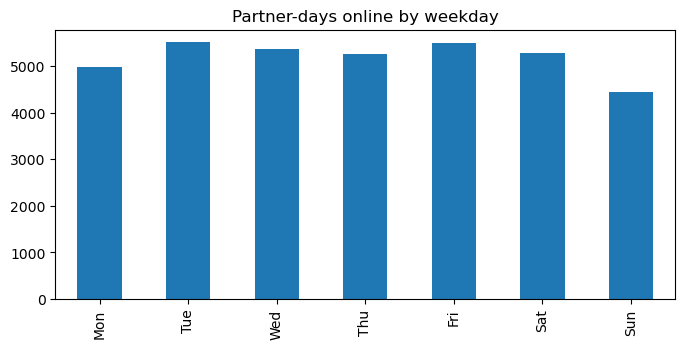

In [5]:
dow = d.groupby('dow').agg(partner_days=('pid','size'), avg_hours=('hours','mean'), avg_tasks=('tasks','mean'))
dow.index = DAYS
display(dow.round(2))
dow.partner_days.plot.bar(title='Partner-days online by weekday'); plt.show()

**Finding:** supply is almost flat across weekdays, yet demand peaks Sun/Mon (then Fri/Sat). Sun and Mon actually have the *fewest* partner-days (the two days with highest demand). Weekday-differentiated rates are therefore the right lever to shift supply toward peak days.

## 1.4 How long should we pay for? (productivity vs hours)

,n,avg_tasks
hours,,
"(0, 2]",2977,2.19
"(2, 4]",3441,4.53
"(4, 6]",5060,8.48
"(6, 8]",5981,12.45
"(8, 10]",7710,15.02
"(10, 12]",6828,15.48
"(12, 14]",3640,14.39
"(14, 24]",642,13.77
"(24, 100]",34,9.09


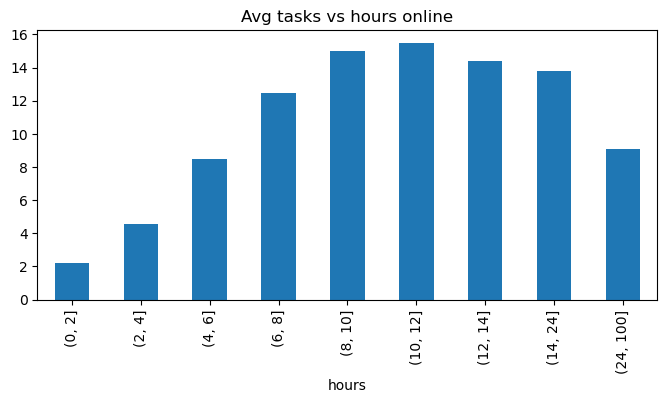

In [6]:
b = pd.cut(d.hours, [0,2,4,6,8,10,12,14,24, 100])
eff = d.groupby(b, observed=True).agg(n=('tasks','size'), avg_tasks=('tasks','mean'))
display(eff.round(2)); eff.avg_tasks.plot.bar(title='Avg tasks vs hours online'); plt.show()

**Finding:** tasks per day plateau at ~15 beyond 8-10 hours; hours beyond 12 add nothing, so **12 hrs/day is the cap**. Paying for them is pure cost.

## 1.5 Consistency: how many days per week do partners show up?

date
1    16.8
2    14.1
3    11.8
4    12.6
5    15.2
6    15.5
7    14.0
Name: % of partner-weeks (4+ hr days), dtype: float64


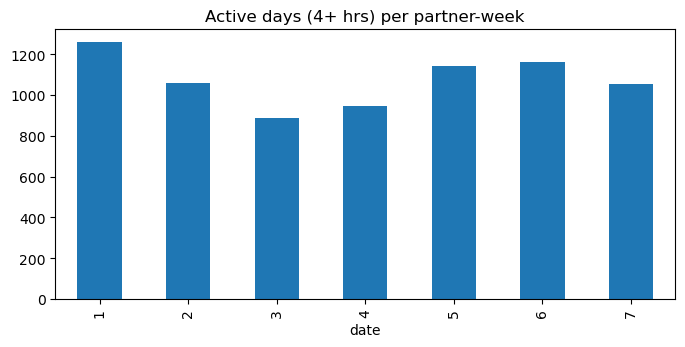

In [7]:
x = d[d.hours >= 4]
wk = x.groupby(['week','pid']).date.nunique()
print((wk.value_counts(normalize=True).sort_index()*100).round(1).rename('% of partner-weeks (4+ hr days)'))
wk.value_counts().sort_index().plot.bar(title='Active days (4+ hrs) per partner-week'); plt.show()

**Finding:** a large share of partner-weeks have 5-7 active days (core) but a big group also appears only 1-2 days. A weekly bonus for 5+ and 7 active days rewards the consistent group and nudges the occasional group up.

## 1.6 Proposed point structure

**1 point = Rs 1.** Four rules, easy to explain to partners:

| Rule | Value |
|---|---|
| Points per online hour: **Sun & Mon** | **1.5** |
| Points per online hour: **Fri & Sat** | **1.0** |
| Points per online hour: **Tue, Wed, Thu** | **0.5** |
| Bonus: 4+ hrs online on **5 days** of the week | **+10 points** |
| Bonus: 4+ hrs online on **all 7 days** | **+25 points** |
| Max hours counted per day | 12 |

Rates 3:2:1 mirror the stated demand order (Sun/Mon > Fri/Sat > Tue-Thu).

In [8]:
P = DEFAULT_PARAMS; print(P)
x, wkb = points(d, P)
print('Typical partner example: 8 hrs each day all week ->',
      sum(8*rate_map(P['rates'])[i] for i in range(7)) + P['bonus7'], 'points')

{'rates': {'Sun/Mon': 1.5, 'Fri/Sat': 1.0, 'Tue-Thu': 0.5}, 'cap': 12, 'active_min': 4, 'bonus5': 10, 'bonus7': 25}
Typical partner example: 8 hrs each day all week -> 77.0 points


## 1.7 Budget summary: CPT impact for all 4 months

In [10]:
base = budget(d, P)

out = base[['tasks', 'base_pts', 'bonus_pts', 'total_pts', 'CPT']].round(3)

display(out)

print('Worst month CPT:', round(base.CPT.max(), 3), '(limit 0.9)')

,tasks,base_pts,bonus_pts,total_pts,CPT
month,,,,,
2019-01,86825.0,50779.196,7765.0,58544.196,0.674
2019-02,103865.0,60486.526,12880.0,73366.526,0.706
2019-03,112178.0,72541.498,15695.0,88236.498,0.787
2019-04,119677.0,68623.733,13060.0,81683.733,0.683


Worst month CPT: 0.787 (limit 0.9)


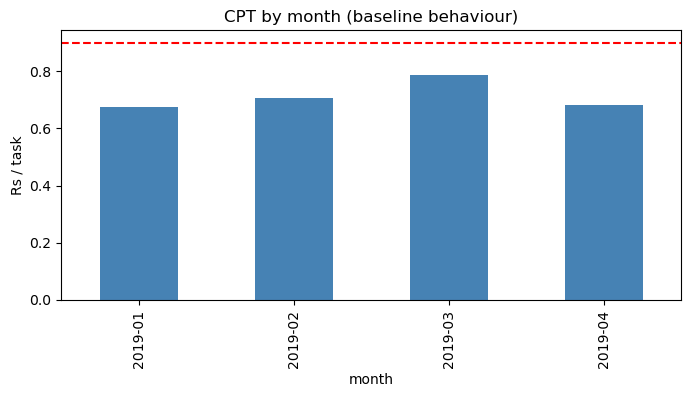

In [11]:
ax = base.CPT.plot.bar(color='steelblue', title='CPT by month (baseline behaviour)'); ax.axhline(0.9, color='red', ls='--'); ax.set_ylabel('Rs / task'); plt.show()

## 1.8 Stress test: will the program stay under 0.9 if partners respond?

In [12]:
scen = {'Baseline': (0,0,0), 'Moderate (+10% hrs, +5% tasks, +25% bonus)': (.10,.05,.25),
        'Aggressive (+20% hrs, +8% tasks, +50% bonus)': (.20,.08,.50),
        'Extreme (+30% hrs, +10% tasks, +100% bonus)': (.30,.10,1.0)}
res = pd.DataFrame({k: budget(d, P, *v).CPT for k, v in scen.items()}).round(3)
display(res); display(res.max().rename('worst-month CPT'))

,Baseline,"Moderate (+10% hrs, +5% tasks, +25% bonus)","Aggressive (+20% hrs, +8% tasks, +50% bonus)","Extreme (+30% hrs, +10% tasks, +100% bonus)"
month,,,,
2019-01,0.674,0.719,0.774,0.854
2019-02,0.706,0.758,0.819,0.914
2019-03,0.787,0.844,0.913,1.019
2019-04,0.683,0.731,0.789,0.876


Baseline                                        0.787
Moderate (+10% hrs, +5% tasks, +25% bonus)      0.844
Aggressive (+20% hrs, +8% tasks, +50% bonus)    0.913
Extreme (+30% hrs, +10% tasks, +100% bonus)     1.019
Name: worst-month CPT, dtype: float64

Extra hours give diminishing extra tasks (section 1.4), so CPT rises under behavioural response. Results: worst-month CPT is **0.787 baseline and 0.844 under the moderate response**, both under 0.9. Under the aggressive response March reaches ~0.91 and the extreme case breaches in Feb-Mar, so the **budget guardrail in 1.10 is part of the design**, not optional.

## 1.9 Sensitivity: why these numbers?

In [13]:
rows=[]
for a,b_,c_ in [(1,1,1),(2,1,0.5),(1.5,1,0.5),(1.5,1,0.75),(2,1.5,1)]:
    for b5,b7 in [(0,0),(10,25),(20,40)]:
        pp = dict(rates={'Sun/Mon':a,'Fri/Sat':b_,'Tue-Thu':c_}, cap=12, active_min=4, bonus5=b5, bonus7=b7)
        bb = budget(d, pp); st_ = budget(d, pp, .10, .05, .25)
        rows.append((f'{a}/{b_}/{c_}', f'{b5}/{b7}', bb.CPT.max(), st_.CPT.max()))
sens = pd.DataFrame(rows, columns=['rates Sun-Mon/Fri-Sat/Tue-Thu','bonus 5d/7d','worst CPT base','worst CPT stress']).round(3)
sens['feasible'] = sens['worst CPT stress'] < 0.9
sens

,rates Sun-Mon/Fri-Sat/Tue-Thu,bonus 5d/7d,worst CPT base,worst CPT stress,feasible
0,1/1/1,0/0,0.686,0.719,True
1,1/1/1,10/25,0.821,0.881,True
2,1/1/1,20/40,0.931,1.011,False
3,2/1/0.5,0/0,0.742,0.777,True
4,2/1/0.5,10/25,0.882,0.943,False
5,2/1/0.5,20/40,0.991,1.074,False
6,1.5/1/0.5,0/0,0.647,0.677,True
7,1.5/1/0.5,10/25,0.787,0.844,True
8,1.5/1/0.5,20/40,0.896,0.974,False
9,1.5/1/0.75,0/0,0.712,0.745,True


Chosen option **1.5/1/0.5 with 10/25 bonus**: is the richest option that still passes the stress test (worst month 0.787 base / 0.844 moderate stress). Richer options (e.g. 2/1/0.5 or 20/40 bonus) fail under stress; poorer ones weaken the incentive. A flat 1/1/1 rate with the same bonus fails to differentiate peak days and costs more (0.821 base).

## 1.10 Guardrails (recommended)
* Monthly points budget = 0.85 x tasks; if projected spend crosses it mid-month, scale all rates pro-rata.
* Points only on days with at least 1 completed task (avoid idle-online gaming).
* March is the costliest month (most hours per task) and is the stress-test benchmark.

# PART 2: Partner Quality Model

## 2.1 Load & audit

In [14]:
q = load_quality()
print(q.shape, '| unique partners:', q.pid.nunique())
print('missing:', q.isna().sum()[lambda s: s>0].to_dict())
print('partners with <10 tasks:', (q.tasks<10).mean().round(3))
print('tasks_not_delivered values:', q.tnd.value_counts().to_dict(), '<- raw column is a COUNT, converted to % of tasks')
q.describe(percentiles=[.05,.5,.95]).T.round(2)

(3553, 11) | unique partners: 3553
missing: {'rating': 46}
partners with <10 tasks: 0.232
tasks_not_delivered values: {0: 3449, 1: 100, 2: 2, 3: 1, 4: 1} <- raw column is a COUNT, converted to % of tasks


,count,mean,std,min,5%,50%,95%,max
pid,3553.0,243112.00,1025.81,241336.00,241513.60,243112.00,244710.40,244888.00
tasks,3553.0,34.27,30.33,2.00,3.00,26.00,99.00,186.00
acc,3553.0,89.73,14.23,8.70,60.00,94.67,100.00,100.00
canc,3553.0,1.51,4.64,0.00,0.00,0.00,7.69,64.58
tnd,3553.0,0.03,0.19,0.00,0.00,0.00,0.00,4.00
pcanc,3553.0,0.48,2.04,0.00,0.00,0.00,2.82,33.33
ttime,3553.0,42.68,20.67,2.94,20.99,41.90,66.90,759.59
inter,3553.0,41.33,17.53,0.00,7.88,41.67,67.65,100.00
contact,3553.0,12.21,12.78,0.00,0.00,9.38,35.71,100.00
rating,3507.0,4.70,0.33,1.00,4.09,4.76,5.00,5.00


**Data notes**
* One row per partner for the week (no date column), so no trend can be built; this is a snapshot model.
* 46 partners have no rating (median-imputed, scored neutrally).
* *Tasks not delivered* is a small count (0-4), not a %, despite the description. Converted to % of tasks.
* Task time has extreme outliers (up to 760 min); anchors clip them.
* ~23% of partners have <10 tasks; their rates are noisy, handled separately.

## 2.2 Relationships between metrics

,tasks,acc,canc,tnd_pct,pcanc,ttime,inter,contact,rating
tasks,1.00,0.20,-0.16,-0.01,-0.05,-0.30,0.07,-0.17,0.05
acc,0.20,1.00,-0.03,-0.03,-0.11,-0.18,0.05,-0.11,0.06
canc,-0.16,-0.03,1.00,-0.01,-0.02,0.04,-0.03,0.02,-0.02
tnd_pct,-0.01,-0.03,-0.01,1.00,-0.00,0.04,-0.00,0.04,-0.17
pcanc,-0.05,-0.11,-0.02,-0.00,1.00,0.04,-0.01,0.03,-0.06
ttime,-0.30,-0.18,0.04,0.04,0.04,1.00,-0.03,0.33,-0.17
inter,0.07,0.05,-0.03,-0.00,-0.01,-0.03,1.00,0.02,-0.04
contact,-0.17,-0.11,0.02,0.04,0.03,0.33,0.02,1.00,-0.10
rating,0.05,0.06,-0.02,-0.17,-0.06,-0.17,-0.04,-0.10,1.00


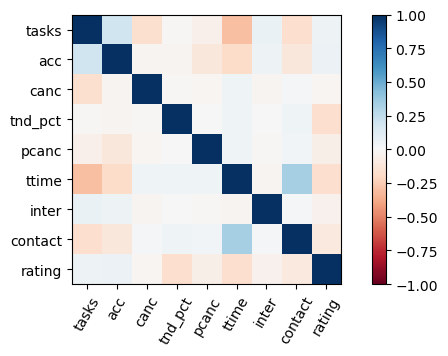

In [15]:
cm = q[['tasks','acc','canc','tnd_pct','pcanc','ttime','inter','contact','rating']].corr().round(2)
display(cm)
plt.imshow(cm, cmap='RdBu', vmin=-1, vmax=1); plt.xticks(range(len(cm)), cm.columns, rotation=60); plt.yticks(range(len(cm)), cm.columns); plt.colorbar(); plt.show()

**Finding:** metrics are only weakly correlated (|r| mostly < 0.3), so each captures a different aspect and should have its own weight rather than dropping any as redundant. Slower task time goes with lower rating (-0.17) and more customer contact (+0.33).

## 2.3 Model design

**Partner Quality Score (0-100) = weighted sum of eight 0-1 sub-scores**; each sub-score is linear between a 'bad' and a 'good' anchor.

| Metric | Weight | Why | Bad -> Good anchor |
|---|---|---|---|
| Customer rating | 25 | Direct voice of the customer | 3.5 -> 5.0 |
| Acceptance rate | 15 | Reliability: takes assigned work | 60% -> 100% |
| Tasks not delivered | 15 | Worst service failure | 3% -> 0% |
| Partner-induced cancellation | 15 | Fully partner-controllable | 5% -> 0% |
| Cancellation rate | 10 | Reliability after accepting | 10% -> 0% |
| Task time | 10 | Efficiency (but depends on distance) | 70 -> 25 min |
| Support interaction rate | 5 | Friction/cost to ops (partly external) | 70% -> 10% |
| Customer contact rate | 5 | Often legitimate (address issues) | 40% -> 0% |

Weights favour metrics the partner **controls** and the customer **feels**; contact/interaction metrics get low weights because they are partly caused by customers and restaurants.

In [16]:
print(DEFAULT_Q)
s = quality_score(q)
s.score.describe().round(1)

{'rating': (25, 3.5, 5.0), 'acc': (15, 60, 100), 'tnd_pct': (15, 3, 0), 'pcanc': (15, 5, 0), 'canc': (10, 10, 0), 'ttime': (10, 70, 25), 'inter': (5, 70, 10), 'contact': (5, 40, 0)}


count    3553.0
mean       81.2
std         9.9
min        23.7
25%        76.1
50%        83.2
75%        88.0
max       100.0
Name: score, dtype: float64

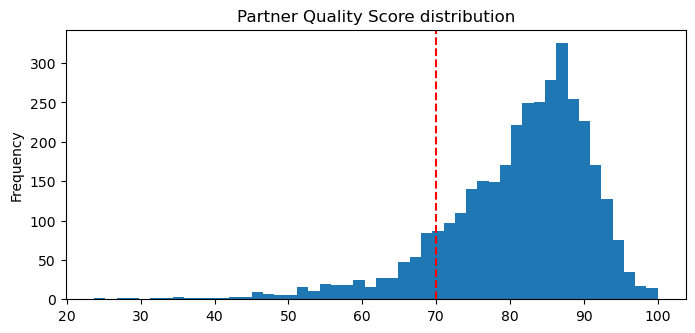

In [17]:
s.score.plot.hist(bins=50, title='Partner Quality Score distribution'); plt.axvline(70, color='red', ls='--'); plt.show()

## 2.4 Threshold selection

In [18]:
rows=[(t, (s.score<t).mean(), s[s.score<t].tasks.median(), s[s.score<t].rating.mean(), s[s.score>=t].rating.mean()) for t in [55,60,65,70,75,80]]
pd.DataFrame(rows, columns=['threshold','% of fleet flagged','median tasks of flagged','avg rating flagged','avg rating rest']).round(3)

,threshold,% of fleet flagged,median tasks of flagged,avg rating flagged,avg rating rest
0,55,0.021,9.0,3.872,4.716
1,60,0.041,9.0,3.955,4.730
2,65,0.063,11.0,4.098,4.738
3,70,0.121,12.0,4.274,4.756
4,75,0.223,14.0,4.418,4.778
5,80,0.362,18.0,4.516,4.801


**Threshold = 70.** It flags 12% of the fleet on raw score (about 9.4% retrain after the low-volume rule below, plus 2.7% on watch), a realistic training capacity. 65 flags only 6% and misses clearly weak partners; 75 flags 22% and 80 flags 36%, which dilutes training and penalises mostly-fine partners. Flagged partners average rating 4.39 vs 4.76 and acceptance 76% vs 92% for the rest. Review threshold quarterly.

**Low-volume rule:** partners with <10 tasks have noisy rates, so a single cancelled task can swing the score massively. They go to retraining only if score < 60 (severe), else to a "watch" list.

In [19]:
s.bucket.value_counts()

bucket
OK                              3124
Retrain                          258
Watch (low volume)                95
Retrain (severe, low volume)      76
Name: count, dtype: int64

In [20]:
s[s.bucket.str.startswith('Retrain')].sort_values('score').head(15)[['pid','tasks','score','bucket','rating','acc','pcanc','tnd_pct','ttime']].round(2)

,pid,tasks,score,bucket,rating,acc,pcanc,tnd_pct,ttime
3496,244832,11,23.70,Retrain,3.40,62.96,5.88,0.00,73.08
3460,244796,5,27.44,"Retrain (severe, low volume)",3.60,69.23,22.22,0.00,76.84
1072,242408,28,28.74,Retrain,3.14,75.00,5.13,3.57,28.25
2072,243408,5,31.49,"Retrain (severe, low volume)",4.00,54.55,0.00,20.00,48.62
3409,244745,3,33.68,"Retrain (severe, low volume)",3.00,75.00,0.00,33.33,132.46
3421,244757,9,34.69,"Retrain (severe, low volume)",3.67,73.33,9.09,0.00,57.44
497,241833,16,34.83,Retrain,3.57,55.56,10.00,0.00,52.79
3255,244591,11,35.83,Retrain,4.00,40.48,5.88,0.00,83.65
1658,242994,8,36.74,"Retrain (severe, low volume)",3.00,66.67,20.00,0.00,56.09
3469,244805,4,38.33,"Retrain (severe, low volume)",4.00,41.67,20.00,0.00,75.66


## 2.5 Why are partners flagged? (root causes to target retraining)

In [21]:
sub = [c for c in s.columns if c.startswith('s_')]
r = s[s.bucket=='Retrain']
gap = ((1 - r[sub]) * pd.Series({f's_{k}': v[0] for k, v in DEFAULT_Q.items()}) / 100 * 100).mean().sort_values(ascending=False)
gap.rename('avg points lost (retraining bucket)').round(2)

s_rating     10.10
s_acc         8.21
s_ttime       5.62
s_pcanc       4.70
s_inter       2.89
s_canc        2.26
s_contact     1.88
s_tnd_pct     1.74
Name: avg points lost (retraining bucket), dtype: float64

Biggest point losses are **customer rating (~10 pts), acceptance (~8) and task time (~5.6)**. Training should therefore focus on customer handling, accepting assigned orders, and delivery speed. Non-delivery rarely drives flags (it is rare, ~1% of partners).

## 2.6 Plan of action: repeat retraining

| Times in retraining bucket | Action |
|---|---|
| 1st | Short refresher module + in-app tips on their 2 weakest metrics; 2-week watch |
| 2nd | Mandatory classroom/video retraining + buddy ride-along; **program points paused until completed** |
| 3rd | Final warning, 1:1 call with city ops, reduced order-allocation priority for 2 weeks |
| 4th | 7-day temporary deactivation and re-onboarding; permanent exit if no improvement |

Partners who score above 70 for 4 consecutive weeks reset their counter. Link to Part 1: points are withheld only at stage 2, so the incentive reinforces the quality behaviour.

# Conclusions

1. **Program:** 1.5 / 1 / 0.5 points per hour (Sun-Mon / Fri-Sat / Tue-Thu), +10 for 5 active days, +25 for 7, 12 hrs/day cap.
2. **Budget:** CPT stays below 0.9 in all four months, with headroom under behavioural stress.
3. **Quality:** 8-metric weighted score, retraining below 70, escalating plan for repeats.
4. **Next steps:** A/B pilot in one zone, track supply hours on peak days, re-tune quarterly.